Loading the dataset

In [8]:
import pandas as pd
import numpy as np

# microdata_filepath = r"G:\My Drive\CIND820 - Capstone Project\Chs2022ecl_pumf.csv"
# bootstrap_filepath = r"G:\My Drive\CIND820 - Capstone Project\Chs2022ecl_pumf_bsw.csv"

microdata_filepath = r'/Users/daniel_ac19hotmail.com/Library/CloudStorage/GoogleDrive-daniel.aquino@torontomu.ca/My Drive/CIND820 - Capstone Project/Chs2022ecl_pumf.csv'
bootstrap_filepath = r'/Users/daniel_ac19hotmail.com/Library/CloudStorage/GoogleDrive-daniel.aquino@torontomu.ca/My Drive/CIND820 - Capstone Project/Chs2022ecl_pumf_bsw.csv'

In [9]:
# Inspecting the data structure for microdata

df = pd.read_csv(microdata_filepath)

print("Number of rows and columns:", df.shape)
print("Unique IDs:", df["PUMFID"].nunique())
print("Missing IDs:", df["PUMFID"].isna().sum())
print("Duplicate IDs:", df["PUMFID"].duplicated().sum())
print("Columns:", df.columns.tolist())

Number of rows and columns: (38657, 103)
Unique IDs: 38657
Missing IDs: 0
Duplicate IDs: 0
Columns: ['PUMFID', 'EHA_10', 'EHA_25', 'FP_05', 'DWI_05A', 'DWI_05B', 'DWI_05C', 'DWI_05D', 'NEI_05A', 'NEI_05B', 'NEI_05C', 'NEI_05D', 'NEI_05E', 'NEI_05F', 'NEI_05G', 'NEI_05H', 'NEI_05I', 'WSA_05', 'SDH_05', 'CER_05', 'CER_20', 'LIS_10', 'COS_10', 'COS_15', 'GH_05', 'GH_10', 'REGION', 'PMINOR', 'PAGEP1', 'PCER_10', 'PCER_15', 'PCHN', 'PCOS_05', 'PDCT_05', 'P1DCT_20', 'P1DCT_25', 'PDV_SAH', 'PDV_SHCO', 'PDV_SUIT', 'PDWLTYPE', 'PDWS_05', 'PDWS_10A', 'PDWS_10B', 'PDWS_10C', 'PDWS_10D', 'PDWS_10E', 'PDWS_10F', 'PDWS_10G', 'PDWS_10H', 'PDWS_10I', 'PDWS_10J', 'PEHA_05A', 'PEHA_05B', 'PEHA_05C', 'PEMPL', 'PFTHB5YR', 'PFWEIGHT', 'PHGEDUC', 'PHHSIZE', 'PHHTTINC', 'PHTYPE', 'PLIS_05', 'PNES_05', 'PNSC_15', 'POWN_20', 'POWN_80', 'PPAC_05', 'PPAC_10', 'PPAC_23', 'PPAC_30', 'PPAC_35', 'PPAC_45A', 'PPAC_45C', 'PPAC_45D', 'PPAC_45E', 'PPAC_45F', 'PPAC_45G', 'PPAC_45H', 'PPAC_45I', 'PPAC_45J', 'PPAC_45K', 'P

In [10]:
# Inspecting the data structure for the bootstrap file

bsw_columns = pd.read_csv(bootstrap_filepath, nrows=0).columns
bsw_ids = pd.read_csv(bootstrap_filepath, usecols=["PUMFID"])

# as the data is large, I will only show the first 5 and last 3 headers.
print(len(bsw_columns), bsw_columns[:5].tolist(), bsw_columns[-3:].tolist())

# to check that both files have the same IDs
print("Same household IDs:", set(df.PUMFID) == set(bsw_ids.PUMFID))

# to check duplicates in the IDs
print("Duplicate bootstrap IDs:", bsw_ids["PUMFID"].duplicated().sum())



1001 ['PUMFID', 'BSW1', 'BSW2', 'BSW3', 'BSW4'] ['BSW998', 'BSW999', 'BSW1000']
Same household IDs: True
Duplicate bootstrap IDs: 0


In [11]:
# Applying binary classification

# count and sort the affordability-satisfaction column
print(df["PDWS_10C"].value_counts(dropna=False).sort_index())

# assign 0 as 'other stated reponse' and 1 as 'dissatisfied'
df["dissatisfied"] = df["PDWS_10C"].map({1:0,2:0, 3:0, 4:1})

analysis = df[df["dissatisfied"].notna()].copy()
print("Valid target records:", len(analysis))
print("Dissatisfied records:", int(analysis["dissatisfied"].sum()))

PDWS_10C
1    10645
2    16550
3     6649
4     4505
9      308
Name: count, dtype: int64
Valid target records: 38349
Dissatisfied records: 4505


/var/folders/3c/y5y29tls74zcqfz9lkh94_d80000gn/T/ipykernel_46622/4070723195.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["dissatisfied"] = df["PDWS_10C"].map({1:0,2:0, 3:0, 4:1})


### DATA PROFILING & AUDIT

In [12]:
# Calculating the main weighted percentage

raw_pct = 100 * analysis["dissatisfied"].mean()
weighted_pct = 100 * np.average(
    analysis["dissatisfied"], weights=analysis["PFWEIGHT"]
)

print(f"Unweighted: {raw_pct:.1f}%")
print(f"Weighed: {weighted_pct:.1f}%")

Unweighted: 11.7%
Weighed: 14.6%


In [14]:
# Reserved missing value codes

reserved = {
    "PDWS_10C": 9,
    "PDCT_05":9,
    "PHHTTINC": 99999999999,
    "PHHSIZE": 99,
    "PDWLTYPE": 99,
    "PDV_SHCO": 9999999.99,
}

for variable, code in reserved.items():
    count = int((df[variable] == code).sum())
    print(f"{variable}: {count:,} reserved values ({100*count/len(df):.1f}%)")

PDWS_10C: 308 reserved values (0.8%)
PDCT_05: 539 reserved values (1.4%)
PHHTTINC: 2,026 reserved values (5.2%)
PHHSIZE: 1,568 reserved values (4.1%)
PDWLTYPE: 1,605 reserved values (4.2%)
PDV_SHCO: 2,704 reserved values (7.0%)


In [15]:
# Percentage of Affordability dissatisfaction by Dwelling Ownership
ownership_labels = {1: "Onwer by member", 2: "Not owned by member"}
analysis["ownership"] = analysis["PDCT_05"].map(ownership_labels)

def weighted_rate(group):
    return 100 * np.average(group["dissatisfied"], weights=group["PFWEIGHT"])

for name, group in analysis.dropna(subset=["ownership"]).groupby("ownership"):
    print(name, "n=", len(group),"weighted rate =", f"{weighted_rate(group):.1f}%")



Not owned by member n= 21546 weighted rate = 20.8%
Onwer by member n= 16267 weighted rate = 11.3%


In [16]:
# Percentage of Affordability dissatisfaction by Province
province_labels = {
    10: "Newfoundland and Labrador",
    11: "Prince Edward Island",
    12: "Nova Scotia",
    13: "New Brunswick",
    24: "Quebec",
    35: "Ontario",
    46: "Manitoba",
    47: "Saskatchewan",
    48: "Alberta",
    59: "British Columbia",
}

analysis["province"] = analysis["PPROV"].map(province_labels)

for name, group in analysis.dropna(subset=["province"]).groupby("province"):
    print(name, "n=", len(group), "weighted rate=", f"{weighted_rate(group):.1f}%")

Alberta n= 4757 weighted rate= 15.3%
British Columbia n= 3836 weighted rate= 21.8%
Manitoba n= 2612 weighted rate= 10.2%
New Brunswick n= 3198 weighted rate= 9.2%
Newfoundland and Labrador n= 2812 weighted rate= 7.1%
Nova Scotia n= 3032 weighted rate= 11.0%
Ontario n= 7311 weighted rate= 16.7%
Prince Edward Island n= 1682 weighted rate= 8.3%
Quebec n= 5256 weighted rate= 9.2%
Saskatchewan n= 3853 weighted rate= 11.3%


In [17]:
# Percentage of Affordability dissatisfaction by Household size
household_size_labels = {
    1: "1 person",
    2: "2 people",
    3: "3 people",
    4: "4 people",
    5: "5 or more people",
}
analysis["household_size"] = analysis["PHHSIZE"].map(household_size_labels)

for name, group in analysis.dropna(subset=["household_size"]).groupby("household_size"):
    print(name, "n=", len(group), "weighted rate =", f"{weighted_rate(group):.1f}%")

1 person n= 16700 weighted rate = 14.6%
2 people n= 11894 weighted rate = 12.8%
3 people n= 3727 weighted rate = 15.2%
4 people n= 2885 weighted rate = 15.5%
5 or more people n= 1585 weighted rate = 16.6%


In [18]:
# Percentage of Affordability dissatisfacion by Annual household income groups
income = analysis["PHHTTINC"].replace(99999999999, np.nan)

analysis["income_group"] = pd.cut(
    income,
    bins=[-np.inf, 50000, 100000, 150000, np.inf],
    labels=["Up to $50k", "$50k-$100k", "$100k-$150k", "Over $150k"],
)

for name, group in analysis.dropna(subset=["income_group"]).groupby(
    "income_group", observed=True
):
    print(name, "n=", len(group), "weighted rate =", f"{weighted_rate(group):.1f}%")

Up to $50k n= 15632 weighted rate = 13.9%
$50k-$100k n= 10547 weighted rate = 15.4%
$100k-$150k n= 5219 weighted rate = 15.2%
Over $150k n= 4935 weighted rate = 13.7%


### graphs for Data profiling & Audit section

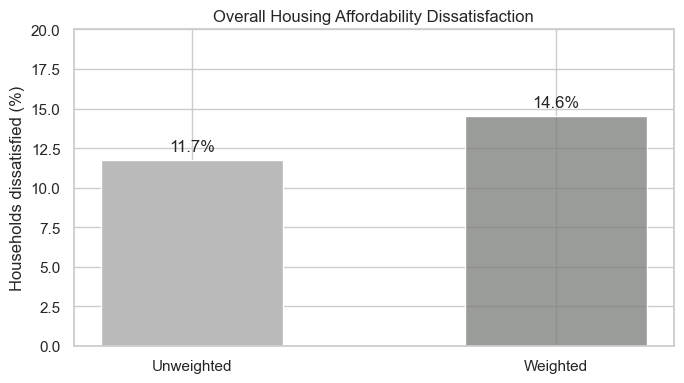

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["Unweighted", "Weighted"],
    [raw_pct, weighted_pct],
    color=["#BBBABA", "#7C7E7AC4"],
    width=0.5
)
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_title("Overall Housing Affordability Dissatisfaction")
ax.set_ylabel("Households dissatisfied (%)")
ax.set_ylim(0, 20)

plt.tight_layout()

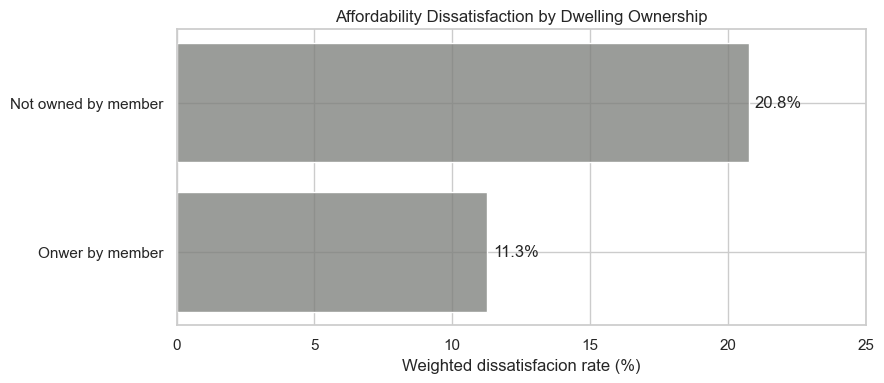

In [46]:
#  Chart 2 - Ownership rates   
ownership_rates = (
    analysis.dropna(subset=["ownership"])
    .groupby("ownership")
    .apply(weighted_rate, include_groups=False)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    ownership_rates.index, 
    ownership_rates.values,
    color="#7C7E7AC4"
)

ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_title("Affordability Dissatisfaction by Dwelling Ownership")
ax.set_xlabel("Weighted dissatisfacion rate (%)")
ax.set_xlim(0, 25)

plt.tight_layout()
plt.show()

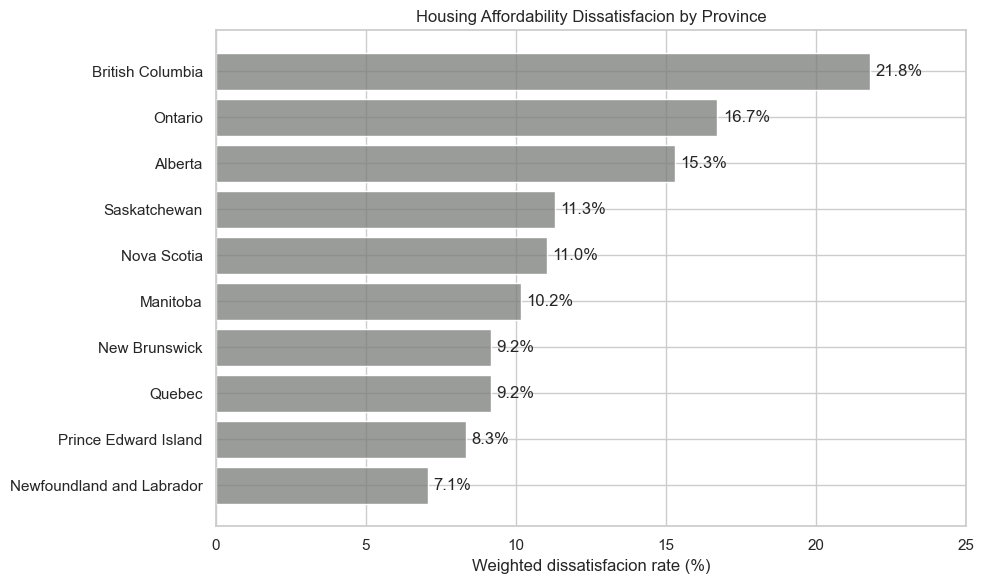

In [45]:
# Chart 3 - Provinces

province_rates = (
    analysis.dropna(subset=["province"])
    .groupby("province")
    .apply(weighted_rate, include_groups=False)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    province_rates.index,
    province_rates.values,
    color="#7C7E7AC4"
)

ax.bar_label(bars, labels=[f"{v:.1f}%" for v in province_rates.values], padding=4)
ax.set_title("Housing Affordability Dissatisfacion by Province")
ax.set_xlabel("Weighted dissatisfacion rate (%)")
ax.set_xlim(0, 25)

plt.tight_layout()
plt.show()

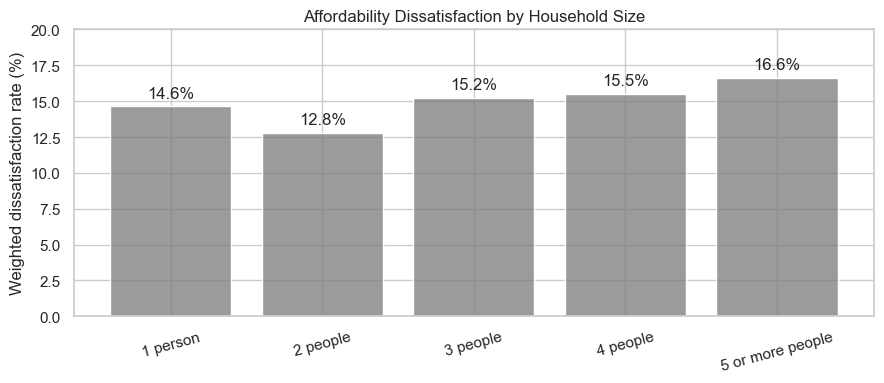

In [44]:
# chart 4 - by house size


size_order = [
    "1 person", "2 people", "3 people",
    "4 people", "5 or more people"
]

size_rates = (
    analysis.dropna(subset=["household_size"])
    .groupby("household_size")
    .apply(weighted_rate, include_groups=False)
    .reindex(size_order)
)

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    size_rates.index,
    size_rates.values,
    color="#7C7E7AC4"
)

ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_title("Affordability Dissatisfaction by Household Size")
ax.set_ylabel("Weighted dissatisfaction rate (%)")
ax.set_ylim(0, 20)
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


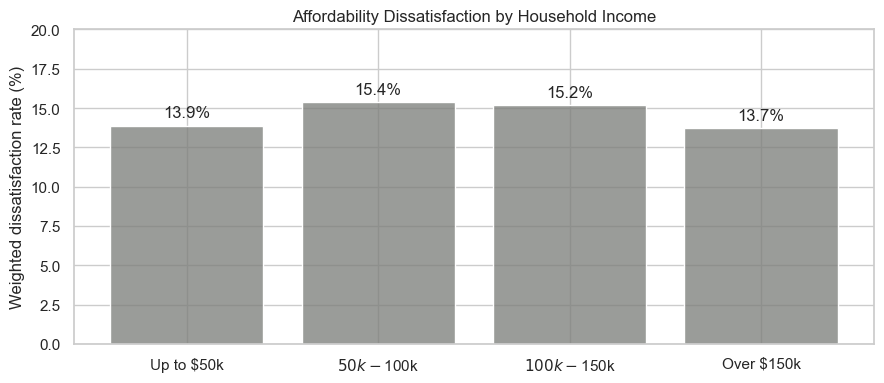

In [41]:
# Chart 5 - Income


income_order = [
    "Up to $50k", "$50k–$100k",
    "$100k–$150k", "Over $150k"
]

income_rates = (
    analysis.dropna(subset=["income_group"])
    .groupby("income_group", observed=True)
    .apply(weighted_rate, include_groups=False)
)

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    income_rates.index,
    income_rates.values,
    color="#7C7E7AC4"
)

ax.bar_label(
    bars,
    labels=[f"{v:.1f}%" for v in income_rates.values],
    padding=4
)
ax.set_title("Affordability Dissatisfaction by Household Income")
ax.set_ylabel("Weighted dissatisfaction rate (%)")
ax.set_ylim(0, 20)

plt.tight_layout()
plt.show()


In [38]:
print(income_rates)


income_group
Up to $50k     13.875935
$50k–$100k           NaN
$100k–$150k          NaN
Over $150k     13.705790
dtype: float64


In [39]:
print(analysis["income_group"].cat.categories.tolist())

['Up to $50k', '$50k-$100k', '$100k-$150k', 'Over $150k']
